In [8]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import os
import random
import json
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms, models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [6]:
# CELL 2 — REPRODUCIBILITY
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Random seed:", SEED)

Random seed: 42


In [7]:
# ============================================================
# CELL 3 — DATASET AND MODEL PATHS
# ============================================================

PROJECT_ROOT = (
    "/content/drive/MyDrive/"
    "Chattogram_Landmark_Dataset"
)

# Dataset
DATASET_ROOT = os.path.join(
    PROJECT_ROOT,
    "06_train_val_test"
)

TRAIN_DIR = os.path.join(
    DATASET_ROOT,
    "train"
)

VAL_DIR = os.path.join(
    DATASET_ROOT,
    "val"
)

TEST_DIR = os.path.join(
    DATASET_ROOT,
    "test"
)

# Model directory
MODEL_ROOT = os.path.join(
    PROJECT_ROOT,
    "07_models"
)

# Requested application folder
APP_MODEL_DIR = os.path.join(
    MODEL_ROOT,
    "Resnet50 App"
)

# Create directory
os.makedirs(
    APP_MODEL_DIR,
    exist_ok=True
)

print("PROJECT_ROOT:")
print(PROJECT_ROOT)

print("\nTRAIN_DIR:")
print(TRAIN_DIR)

print("\nVAL_DIR:")
print(VAL_DIR)

print("\nTEST_DIR:")
print(TEST_DIR)

print("\nRESNET-50 APP MODEL DIRECTORY:")
print(APP_MODEL_DIR)

print("\nPath checks:")
print("Train exists:", os.path.exists(TRAIN_DIR))
print("Val exists:", os.path.exists(VAL_DIR))
print("Test exists:", os.path.exists(TEST_DIR))
print("Model directory exists:", os.path.exists(APP_MODEL_DIR))

PROJECT_ROOT:
/content/drive/MyDrive/Chattogram_Landmark_Dataset

TRAIN_DIR:
/content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/train

VAL_DIR:
/content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/val

TEST_DIR:
/content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/test

RESNET-50 APP MODEL DIRECTORY:
/content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/Resnet50 App

Path checks:
Train exists: True
Val exists: True
Test exists: True
Model directory exists: True


In [ ]:
# CELL 4 — FIND LANDMARK CLASSES


IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".webp"
)

def get_landmark_classes(split_dir):

    classes = set()

    for district in sorted(
        os.listdir(split_dir)
    ):

        district_path = os.path.join(
            split_dir,
            district
        )

        if not os.path.isdir(
            district_path
        ):
            continue

        for landmark in sorted(
            os.listdir(district_path)
        ):

            landmark_path = os.path.join(
                district_path,
                landmark
            )

            if os.path.isdir(
                landmark_path
            ):
                classes.add(landmark)

    return sorted(classes)


train_classes = get_landmark_classes(
    TRAIN_DIR
)

val_classes = get_landmark_classes(
    VAL_DIR
)

test_classes = get_landmark_classes(
    TEST_DIR
)

print("Train classes:", len(train_classes))
print("Validation classes:", len(val_classes))
print("Test classes:", len(test_classes))

Train classes: 58
Validation classes: 58
Test classes: 58


In [ ]:
# ============================================================
# CELL 5 — VERIFY CLASS CONSISTENCY
# ============================================================

print(
    "Missing from TRAIN:",
    sorted(
        set(val_classes + test_classes)
        - set(train_classes)
    )
)

print(
    "Missing from VAL:",
    sorted(
        set(train_classes + test_classes)
        - set(val_classes)
    )
)

print(
    "Missing from TEST:",
    sorted(
        set(train_classes + val_classes)
        - set(test_classes)
    )
)

assert (
    train_classes ==
    val_classes ==
    test_classes
), "ERROR: Train/Val/Test classes do not match!"

CLASS_NAMES = train_classes

NUM_CLASSES = len(
    CLASS_NAMES
)

print("\nNumber of classes:", NUM_CLASSES)

for i, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{i:02d}: {class_name}"
    )

Missing from TRAIN: []
Missing from VAL: []
Missing from TEST: []

Number of classes: 58
00: Adinath_Temple
01: Alutila_Cave
02: Anderkilla_Shahi_Jame_Mosque
03: Anderson_Canal
04: Arifail_Mosque
05: Bajra_Shahi_Mosque
06: Banshbaria_Beach
07: Batali_Hill
08: Bayazid_Bostami_Shrine
09: Boga_Lake
10: Central_Railway_Building
11: Chandanpura_Mosque
12: Chandpur_Stadium
13: Chandranath_Hill
14: Chandranath_Temple
15: Chattogram_Central_Shaheed_Minar
16: Chattogram_Court_Building
17: Chattogram_Railway_Station
18: Chattogram_War_Cemetery
19: Chattogram_Zoo
20: Cheragi_Pahar
21: Chimbuk_Hill
22: Comilla_Cantonment_War_Cemetery
23: Coxs_Bazar_Beach
24: Dalal_Bazar_Jamindar_Bari
25: Dharmasagar_Dighi
26: Dulahazara_Safari_Park
27: Ethnological_Museum
28: Foys_Lake
29: Golden_Temple_Bandarban
30: Guliakhali_Beach
31: Haripur_Barendra_Bari
32: Himchari
33: Inani_Beach
34: Itakhola_Mura
35: Jamboree_Park
36: Kalurghat_Bridge
37: Kaptai_Lake
38: Keokradong
39: Kutubdia_Island
40: Lalmai_Hills
41:

In [ ]:
# ============================================================
# CELL 6 — COUNT IMAGES BY LANDMARK
# ============================================================

def count_images_by_landmark(
    split_dir
):

    counts = {}

    for district in sorted(
        os.listdir(split_dir)
    ):

        district_path = os.path.join(
            split_dir,
            district
        )

        if not os.path.isdir(
            district_path
        ):
            continue

        for landmark in sorted(
            os.listdir(district_path)
        ):

            landmark_path = os.path.join(
                district_path,
                landmark
            )

            if not os.path.isdir(
                landmark_path
            ):
                continue

            count = 0

            for filename in os.listdir(
                landmark_path
            ):

                if filename.lower().endswith(
                    IMAGE_EXTENSIONS
                ):
                    count += 1

            if landmark not in counts:
                counts[landmark] = 0

            counts[landmark] += count

    return pd.Series(
        counts,
        dtype="int64"
    ).sort_index()


train_counts = count_images_by_landmark(
    TRAIN_DIR
)

val_counts = count_images_by_landmark(
    VAL_DIR
)

test_counts = count_images_by_landmark(
    TEST_DIR
)

distribution = pd.DataFrame({

    "Train": train_counts,

    "Validation": val_counts,

    "Test": test_counts

}).fillna(0).astype(int)

distribution["Total"] = (
    distribution["Train"] +
    distribution["Validation"] +
    distribution["Test"]
)

print(
    distribution.to_string()
)

print("\n" + "=" * 70)
print("TOTAL DATASET")
print("=" * 70)

print(
    "Train:",
    train_counts.sum()
)

print(
    "Validation:",
    val_counts.sum()
)

print(
    "Test:",
    test_counts.sum()
)

print(
    "Total:",
    distribution["Total"].sum()
)

                                  Train  Validation  Test  Total
Adinath_Temple                       28           6     6     40
Alutila_Cave                         23           5     5     33
Anderkilla_Shahi_Jame_Mosque         28           6     6     40
Anderson_Canal                       26           6     5     37
Arifail_Mosque                       22           5     4     31
Bajra_Shahi_Mosque                   22           5     5     32
Banshbaria_Beach                     24           5     6     35
Batali_Hill                          28           6     6     40
Bayazid_Bostami_Shrine               28           6     6     40
Boga_Lake                            28           6     6     40
Central_Railway_Building             27           6     6     39
Chandanpura_Mosque                   24           5     6     35
Chandpur_Stadium                     25           5     6     36
Chandranath_Hill                     24           5     6     35
Chandranath_Temple       

In [ ]:
# ============================================================
# CELL 7 — CLASS BALANCE CHECK
# ============================================================

print("=" * 70)
print("CLASS BALANCE CHECK")
print("=" * 70)

print(
    "Minimum total images/class:",
    distribution["Total"].min()
)

print(
    "Maximum total images/class:",
    distribution["Total"].max()
)

print(
    "Mean total images/class:",
    distribution["Total"].mean()
)

print(
    "Median total images/class:",
    distribution["Total"].median()
)

print("\nClasses with fewer than 30 images:")

print(
    distribution[
        distribution["Total"] < 30
    ].to_string()
)

print("\nClasses with more than 40 images:")

print(
    distribution[
        distribution["Total"] > 40
    ].to_string()
)

CLASS BALANCE CHECK
Minimum total images/class: 31
Maximum total images/class: 40
Mean total images/class: 36.8448275862069
Median total images/class: 37.0

Classes with fewer than 30 images:
Empty DataFrame
Columns: [Train, Validation, Test, Total]
Index: []

Classes with more than 40 images:
Empty DataFrame
Columns: [Train, Validation, Test, Total]
Index: []


In [ ]:
# ============================================================
# CELL 8 — CUSTOM LANDMARK DATASET
# ============================================================

class LandmarkDataset(Dataset):

    def __init__(
        self,
        root_dir,
        class_names,
        transform=None
    ):

        self.root_dir = root_dir

        self.class_names = class_names

        self.class_to_idx = {
            name: idx
            for idx, name in enumerate(
                class_names
            )
        }

        self.transform = transform

        self.samples = []

        for district in sorted(
            os.listdir(root_dir)
        ):

            district_path = os.path.join(
                root_dir,
                district
            )

            if not os.path.isdir(
                district_path
            ):
                continue

            for landmark in sorted(
                os.listdir(district_path)
            ):

                landmark_path = os.path.join(
                    district_path,
                    landmark
                )

                if not os.path.isdir(
                    landmark_path
                ):
                    continue

                if landmark not in (
                    self.class_to_idx
                ):
                    continue

                label = self.class_to_idx[
                    landmark
                ]

                for filename in sorted(
                    os.listdir(
                        landmark_path
                    )
                ):

                    if not filename.lower().endswith(
                        IMAGE_EXTENSIONS
                    ):
                        continue

                    image_path = os.path.join(
                        landmark_path,
                        filename
                    )

                    self.samples.append(
                        (
                            image_path,
                            label
                        )
                    )

        print(
            f"{root_dir}: "
            f"{len(self.samples)} images"
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(
        self,
        index
    ):

        image_path, label = (
            self.samples[index]
        )

        try:

            image = Image.open(
                image_path
            ).convert("RGB")

        except Exception as e:

            raise RuntimeError(
                f"Could not read image: "
                f"{image_path}\n{e}"
            )

        if self.transform is not None:

            image = self.transform(
                image
            )

        return image, label

In [ ]:
# ============================================================
# CELL 9 — IMAGE TRANSFORMS
# ============================================================

IMG_SIZE = 224

train_transform = transforms.Compose([

    transforms.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.75, 1.0),
        ratio=(0.85, 1.15)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.ColorJitter(
        brightness=0.20,
        contrast=0.20,
        saturation=0.15,
        hue=0.03
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    ),

    transforms.RandomErasing(
        p=0.15,
        scale=(0.02, 0.10),
        ratio=(0.3, 3.3),
        value="random"
    )
])


val_test_transform = transforms.Compose([

    transforms.Resize(
        256
    ),

    transforms.CenterCrop(
        IMG_SIZE
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

print("Transforms ready.")

Transforms ready.


In [ ]:
# ============================================================
# CELL 10 — CREATE DATASETS
# ============================================================

train_dataset = LandmarkDataset(
    TRAIN_DIR,
    CLASS_NAMES,
    transform=train_transform
)

val_dataset = LandmarkDataset(
    VAL_DIR,
    CLASS_NAMES,
    transform=val_test_transform
)

test_dataset = LandmarkDataset(
    TEST_DIR,
    CLASS_NAMES,
    transform=val_test_transform
)

print("\nFinal dataset sizes:")

print(
    "Train:",
    len(train_dataset)
)

print(
    "Validation:",
    len(val_dataset)
)

print(
    "Test:",
    len(test_dataset)
)

/content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/train: 1488 images
/content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/val: 321 images
/content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/test: 328 images

Final dataset sizes:
Train: 1488
Validation: 321
Test: 328


In [ ]:
# ============================================================
# CELL 11 — DATALOADERS
# ============================================================

BATCH_SIZE = 32
NUM_WORKERS = 2

PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=NUM_WORKERS,

    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=PIN_MEMORY
)

print("DataLoaders created.")

DataLoaders created.


In [ ]:
# ============================================================
# CELL 12 — TEST ONE BATCH
# ============================================================

images, labels = next(
    iter(train_loader)
)

print(
    "Images:",
    images.shape
)

print(
    "Labels:",
    labels.shape
)

print(
    "First labels:",
    labels[:10]
)

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
First labels: tensor([42,  7, 10,  1,  0, 27,  1, 43, 50, 33])


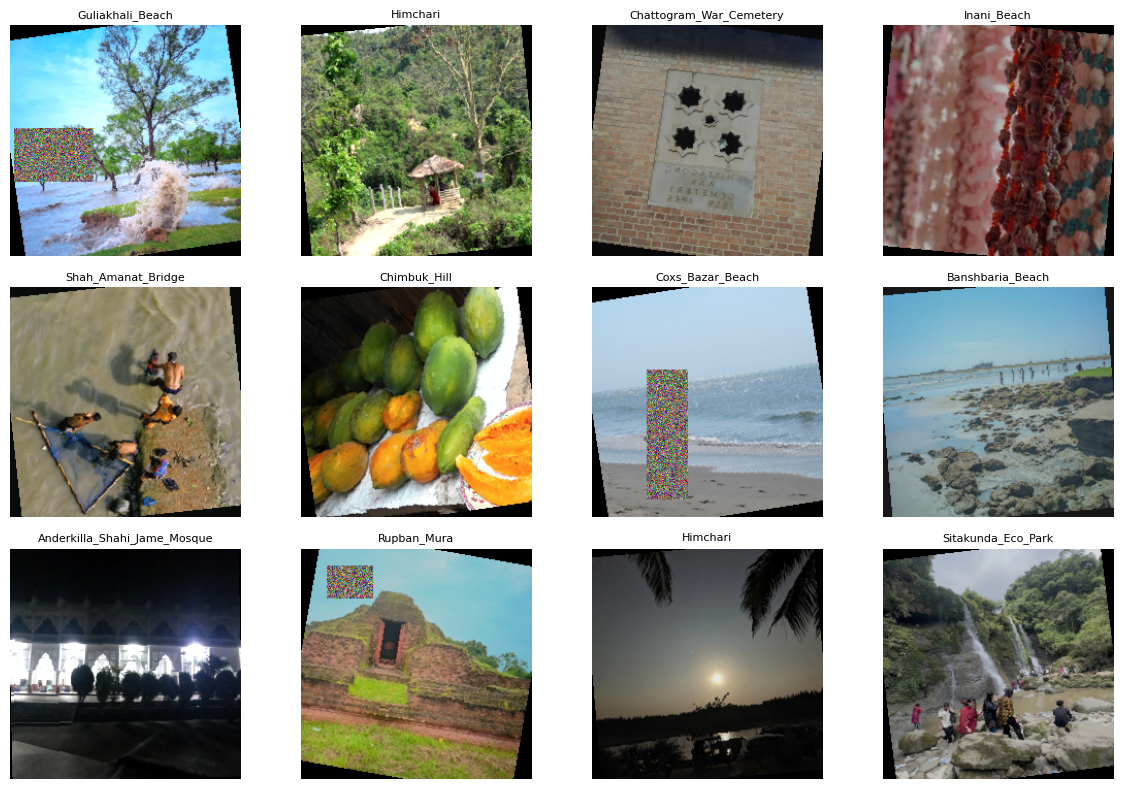

In [ ]:
# ============================================================
# CELL 13 — VISUALIZE TRAINING IMAGES
# ============================================================

def denormalize(image):

    mean = np.array([
        0.485,
        0.456,
        0.406
    ])

    std = np.array([
        0.229,
        0.224,
        0.225
    ])

    image = image.numpy().transpose(
        1, 2, 0
    )

    image = (
        image * std
    ) + mean

    return np.clip(
        image,
        0,
        1
    )


images, labels = next(
    iter(train_loader)
)

plt.figure(
    figsize=(12, 8)
)

for i in range(
    min(12, len(images))
):

    plt.subplot(
        3,
        4,
        i + 1
    )

    image = denormalize(
        images[i].cpu()
    )

    plt.imshow(image)

    plt.title(
        CLASS_NAMES[
            labels[i].item()
        ],
        fontsize=8
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 14 — DEVICE
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(
    "Device:",
    device
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Device: cuda
GPU: Tesla T4


In [ ]:
# ============================================================
# CELL 15 — LOAD PRETRAINED RESNET-50
# ============================================================

weights = (
    models.ResNet50_Weights.DEFAULT
)

model = models.resnet50(
    weights=weights
)

print(
    "Pretrained ResNet-50 loaded."
)

print(
    "Original classifier:",
    model.fc
)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 139MB/s]


Pretrained ResNet-50 loaded.
Original classifier: Linear(in_features=2048, out_features=1000, bias=True)


In [ ]:
# ============================================================
# CELL 16 — REPLACE CLASSIFIER
# ============================================================

in_features = model.fc.in_features

model.fc = nn.Sequential(

    nn.Dropout(
        p=0.50
    ),

    nn.Linear(
        in_features,
        NUM_CLASSES
    )
)

model = model.to(device)

print(
    "New classifier:"
)

print(
    model.fc
)

New classifier:
Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Linear(in_features=2048, out_features=58, bias=True)
)


In [ ]:
# ============================================================
# CELL 17 — PARAMETER COUNT
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "Total parameters:",
    f"{total_params:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_params:,}"
)

Total parameters: 23,626,874
Trainable parameters: 23,626,874


In [ ]:
# ============================================================
# CELL 18 — FREEZE RESNET BACKBONE
# ============================================================

for param in model.parameters():

    param.requires_grad = False


for param in model.fc.parameters():

    param.requires_grad = True


trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    f"{trainable_params:,}"
)

Trainable parameters: 118,842


In [ ]:
# ============================================================
# CELL 19 — LOSS FUNCTION
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.10
)

print(
    criterion
)

CrossEntropyLoss()


In [ ]:
# ============================================================
# CELL 20 — STAGE 1 OPTIMIZER
# ============================================================

optimizer = optim.AdamW(

    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),

    lr=1e-3,

    weight_decay=1e-4
)

scheduler = (
    optim.lr_scheduler.ReduceLROnPlateau(

        optimizer,

        mode="max",

        factor=0.5,

        patience=2,

        min_lr=1e-6
    )
)

print(
    "Stage 1 optimizer ready."
)

Stage 1 optimizer ready.


In [ ]:
# ============================================================
# CELL 20 — STAGE 1 OPTIMIZER
# ============================================================

optimizer = optim.AdamW(

    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),

    lr=1e-3,

    weight_decay=1e-4
)

scheduler = (
    optim.lr_scheduler.ReduceLROnPlateau(

        optimizer,

        mode="max",

        factor=0.5,

        patience=2,

        min_lr=1e-6
    )
)

print(
    "Stage 1 optimizer ready."
)

Stage 1 optimizer ready.


In [ ]:
# ============================================================
# CELL 21 — TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    correct = 0

    total = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        outputs = model(
            images
        )

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = (
            outputs.argmax(
                dim=1
            )
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = (
        running_loss / total
    )

    epoch_accuracy = (
        correct / total
    )

    return (
        epoch_loss,
        epoch_accuracy
    )

In [ ]:
# ============================================================
# CELL 22 — VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_predictions = []

    total = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        outputs = model(
            images
        )

        loss = criterion(
            outputs,
            labels
        )

        running_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = (
            outputs.argmax(
                dim=1
            )
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        total += labels.size(0)

    epoch_loss = (
        running_loss / total
    )

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return (
        epoch_loss,
        epoch_accuracy,
        epoch_macro_f1
    )

In [ ]:
# ============================================================
# CELL 23 — VERIFY MODEL DIRECTORY
# ============================================================

print(
    "Saving models to:"
)

print(
    APP_MODEL_DIR
)

os.makedirs(
    APP_MODEL_DIR,
    exist_ok=True
)

Saving models to:
/content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/Model/Resnet50 App


In [ ]:
# ============================================================
# CELL 24 — RESNET-50 STAGE 1 TRAINING
# ============================================================

STAGE1_EPOCHS = 8
STAGE1_PATIENCE = 3

best_val_f1 = -1.0
patience_counter = 0

stage1_history = []

STAGE1_BEST_PATH = os.path.join(
    APP_MODEL_DIR,
    "ResNet50_Stage1_Best.pth"
)

for epoch in range(
    STAGE1_EPOCHS
):

    start_time = time.time()

    train_loss, train_acc = (
        train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )
    )

    val_loss, val_acc, val_f1 = (
        validate_one_epoch(
            model,
            val_loader,
            criterion,
            device
        )
    )

    scheduler.step(
        val_f1
    )

    lr = optimizer.param_groups[0]["lr"]

    epoch_time = (
        time.time()
        - start_time
    )

    stage1_history.append({

        "stage": "Stage1",

        "epoch": epoch + 1,

        "train_loss": train_loss,

        "train_accuracy": train_acc,

        "val_loss": val_loss,

        "val_accuracy": val_acc,

        "val_macro_f1": val_f1,

        "learning_rate": lr,

        "epoch_time_seconds":
            epoch_time
    })

    print(
        f"Epoch {epoch+1}/{STAGE1_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f} | "
        f"LR: {lr:.2e}"
    )

    # Save BEST based on validation macro-F1
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        patience_counter = 0

        torch.save({

            "model_state_dict":
                model.state_dict(),

            "class_names":
                CLASS_NAMES,

            "num_classes":
                NUM_CLASSES,

            "image_size":
                IMG_SIZE,

            "mean": [
                0.485,
                0.456,
                0.406
            ],

            "std": [
                0.229,
                0.224,
                0.225
            ],

            "stage":
                "Stage1",

            "epoch":
                epoch + 1,

            "val_accuracy":
                val_acc,

            "val_macro_f1":
                val_f1

        }, STAGE1_BEST_PATH)

        print(
            "   ✓ Best Stage 1 checkpoint saved."
        )

    else:

        patience_counter += 1

        print(
            f"   No improvement "
            f"({patience_counter}/"
            f"{STAGE1_PATIENCE})"
        )

        if (
            patience_counter
            >= STAGE1_PATIENCE
        ):

            print(
                "Early stopping Stage 1."
            )

            break

print(
    "\nStage 1 finished."
)

print(
    "Best Stage 1 Macro-F1:",
    best_val_f1
)

Epoch 1/8 | Train Loss: 1.8049 | Train Acc: 0.7372 | Val Loss: 2.4855 | Val Acc: 0.4798 | Val Macro-F1: 0.4630 | LR: 1.00e-03
   ✓ Best Stage 1 checkpoint saved.
Epoch 2/8 | Train Loss: 1.7606 | Train Acc: 0.7386 | Val Loss: 2.4639 | Val Acc: 0.4922 | Val Macro-F1: 0.4700 | LR: 1.00e-03
   ✓ Best Stage 1 checkpoint saved.
Epoch 3/8 | Train Loss: 1.7114 | Train Acc: 0.7621 | Val Loss: 2.4398 | Val Acc: 0.4984 | Val Macro-F1: 0.4852 | LR: 1.00e-03
   ✓ Best Stage 1 checkpoint saved.
Epoch 4/8 | Train Loss: 1.6392 | Train Acc: 0.7876 | Val Loss: 2.4144 | Val Acc: 0.5016 | Val Macro-F1: 0.4907 | LR: 1.00e-03
   ✓ Best Stage 1 checkpoint saved.
Epoch 5/8 | Train Loss: 1.5642 | Train Acc: 0.8011 | Val Loss: 2.4043 | Val Acc: 0.5016 | Val Macro-F1: 0.4880 | LR: 1.00e-03
   No improvement (1/3)
Epoch 6/8 | Train Loss: 1.5668 | Train Acc: 0.7944 | Val Loss: 2.3886 | Val Acc: 0.5078 | Val Macro-F1: 0.4944 | LR: 1.00e-03
   ✓ Best Stage 1 checkpoint saved.
Epoch 7/8 | Train Loss: 1.5028 | Train A

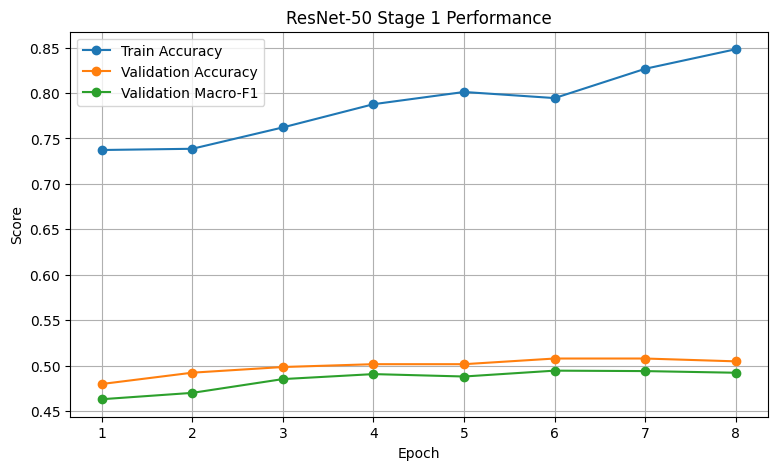

In [ ]:
# ============================================================
# CELL 25 — STAGE 1 ACCURACY/F1
# ============================================================

stage1_df = pd.DataFrame(
    stage1_history
)

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    stage1_df["epoch"],
    stage1_df["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    stage1_df["epoch"],
    stage1_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.plot(
    stage1_df["epoch"],
    stage1_df["val_macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Score")

plt.title(
    "ResNet-50 Stage 1 Performance"
)

plt.legend()
plt.grid(True)
plt.show()

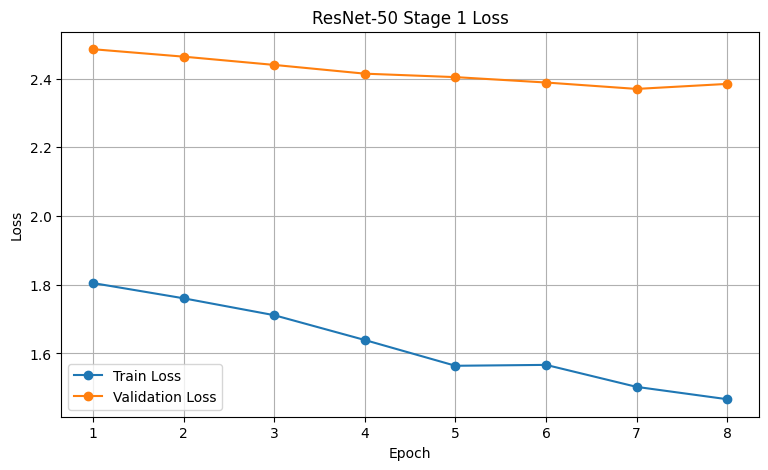

In [ ]:
# ============================================================
# CELL 26 — STAGE 1 LOSS
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    stage1_df["epoch"],
    stage1_df["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    stage1_df["epoch"],
    stage1_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ResNet-50 Stage 1 Loss"
)

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# CELL 27 — LOAD BEST STAGE 1
# ============================================================

checkpoint = torch.load(
    STAGE1_BEST_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)

print(
    "Best Stage 1 checkpoint loaded."
)

print(
    "Best validation accuracy:",
    checkpoint[
        "val_accuracy"
    ]
)

print(
    "Best validation Macro-F1:",
    checkpoint[
        "val_macro_f1"
    ]
)

Best Stage 1 checkpoint loaded.
Best validation accuracy: 0.5077881619937694
Best validation Macro-F1: 0.4944450169535576


In [ ]:
# ============================================================
# CELL 28 — STAGE 2 FINE-TUNING
# ============================================================

# Freeze everything
for param in model.parameters():

    param.requires_grad = False


# Unfreeze ONLY layer4
for param in model.layer4.parameters():

    param.requires_grad = True


# Keep classifier trainable
for param in model.fc.parameters():

    param.requires_grad = True


trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    f"{trainable_params:,}"
)

print(
    "\nTrainable sections:"
)

print(
    "layer4: YES"
)

print(
    "fc: YES"
)

print(
    "layer1-layer3: NO"
)

Trainable parameters: 15,083,578

Trainable sections:
layer4: YES
fc: YES
layer1-layer3: NO


In [ ]:
# ============================================================
# CELL 29 — STAGE 2 OPTIMIZER
# ============================================================

optimizer = optim.AdamW(

    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),

    lr=1e-4,

    weight_decay=5e-4
)

scheduler = (
    optim.lr_scheduler.ReduceLROnPlateau(

        optimizer,

        mode="max",

        factor=0.5,

        patience=2,

        min_lr=1e-7
    )
)

print(
    "Stage 2 optimizer ready."
)

Stage 2 optimizer ready.


In [ ]:
# ============================================================
# CELL 30 — RESNET-50 STAGE 2 TRAINING
# ============================================================

STAGE2_EPOCHS = 12
STAGE2_PATIENCE = 4

best_val_f1 = -1.0
patience_counter = 0

stage2_history = []

FINAL_MODEL_PATH = os.path.join(
    APP_MODEL_DIR,
    "ResNet50_App_Best.pth"
)

for epoch in range(
    STAGE2_EPOCHS
):

    start_time = time.time()

    train_loss, train_acc = (
        train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )
    )

    val_loss, val_acc, val_f1 = (
        validate_one_epoch(
            model,
            val_loader,
            criterion,
            device
        )
    )

    scheduler.step(
        val_f1
    )

    lr = optimizer.param_groups[0]["lr"]

    epoch_time = (
        time.time()
        - start_time
    )

    stage2_history.append({

        "stage": "Stage2",

        "epoch": epoch + 1,

        "train_loss": train_loss,

        "train_accuracy": train_acc,

        "val_loss": val_loss,

        "val_accuracy": val_acc,

        "val_macro_f1": val_f1,

        "learning_rate": lr,

        "epoch_time_seconds":
            epoch_time
    })

    print(
        f"Epoch {epoch+1}/{STAGE2_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f} | "
        f"LR: {lr:.2e}"
    )

    # Save best final model
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        patience_counter = 0

        torch.save({

            "model_state_dict":
                model.state_dict(),

            "class_names":
                CLASS_NAMES,

            "num_classes":
                NUM_CLASSES,

            "image_size":
                IMG_SIZE,

            "mean": [
                0.485,
                0.456,
                0.406
            ],

            "std": [
                0.229,
                0.224,
                0.225
            ],

            "architecture":
                "ResNet50",

            "stage":
                "Stage2",

            "epoch":
                epoch + 1,

            "val_accuracy":
                val_acc,

            "val_macro_f1":
                val_f1

        }, FINAL_MODEL_PATH)

        print(
            "   ✓ BEST ResNet-50 APP MODEL SAVED."
        )

    else:

        patience_counter += 1

        print(
            f"   No improvement "
            f"({patience_counter}/"
            f"{STAGE2_PATIENCE})"
        )

        if (
            patience_counter
            >= STAGE2_PATIENCE
        ):

            print(
                "\nEarly stopping Stage 2."
            )

            break

print(
    "\nStage 2 finished."
)

print(
    "Best validation Macro-F1:",
    best_val_f1
)

print(
    "\nBEST MODEL:"
)

print(
    FINAL_MODEL_PATH
)

Epoch 1/12 | Train Loss: 1.4591 | Train Acc: 0.8253 | Val Loss: 2.3365 | Val Acc: 0.5234 | Val Macro-F1: 0.5115 | LR: 1.00e-04
   ✓ BEST ResNet-50 APP MODEL SAVED.
Epoch 2/12 | Train Loss: 1.3095 | Train Acc: 0.8716 | Val Loss: 2.3374 | Val Acc: 0.5140 | Val Macro-F1: 0.4975 | LR: 1.00e-04
   No improvement (1/4)
Epoch 3/12 | Train Loss: 1.2156 | Train Acc: 0.9079 | Val Loss: 2.3018 | Val Acc: 0.5327 | Val Macro-F1: 0.5186 | LR: 1.00e-04
   ✓ BEST ResNet-50 APP MODEL SAVED.
Epoch 4/12 | Train Loss: 1.1430 | Train Acc: 0.9267 | Val Loss: 2.3057 | Val Acc: 0.5389 | Val Macro-F1: 0.5234 | LR: 1.00e-04
   ✓ BEST ResNet-50 APP MODEL SAVED.
Epoch 5/12 | Train Loss: 1.1179 | Train Acc: 0.9409 | Val Loss: 2.3042 | Val Acc: 0.5327 | Val Macro-F1: 0.5229 | LR: 1.00e-04
   No improvement (1/4)
Epoch 6/12 | Train Loss: 1.0892 | Train Acc: 0.9536 | Val Loss: 2.3064 | Val Acc: 0.5202 | Val Macro-F1: 0.5035 | LR: 1.00e-04
   No improvement (2/4)
Epoch 7/12 | Train Loss: 1.0389 | Train Acc: 0.9677 | V

In [ ]:
# ============================================================
# CELL 31 — SAVE TRAINING HISTORY
# ============================================================

stage1_df = pd.DataFrame(
    stage1_history
)

stage2_df = pd.DataFrame(
    stage2_history
)

full_history = pd.concat(
    [
        stage1_df,
        stage2_df
    ],
    ignore_index=True
)

HISTORY_PATH = os.path.join(
    APP_MODEL_DIR,
    "ResNet50_Training_History.csv"
)

full_history.to_csv(
    HISTORY_PATH,
    index=False
)

print(
    "Training history saved:"
)

print(
    HISTORY_PATH
)

Training history saved:
/content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/Model/Resnet50 App/ResNet50_Training_History.csv


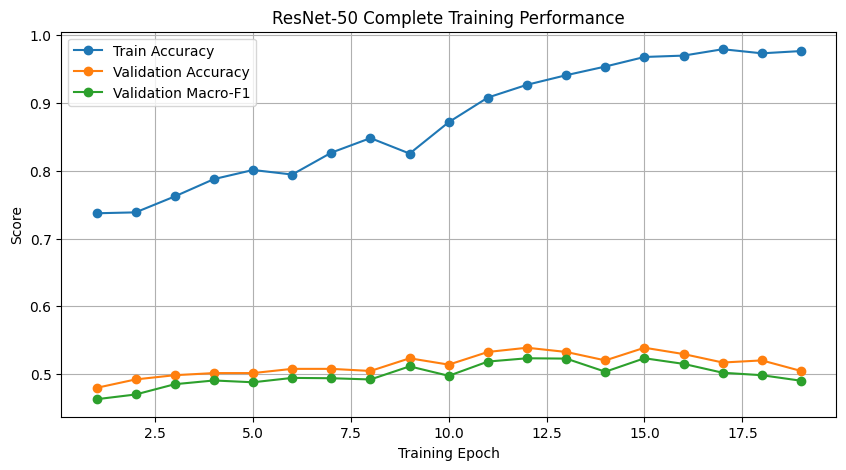

In [ ]:
# ============================================================
# CELL 32 — COMPLETE TRAINING CURVES
# ============================================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    range(1, len(full_history) + 1),
    full_history["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    range(1, len(full_history) + 1),
    full_history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.plot(
    range(1, len(full_history) + 1),
    full_history["val_macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Training Epoch")
plt.ylabel("Score")

plt.title(
    "ResNet-50 Complete Training Performance"
)

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# CELL 33 — OVERFITTING ANALYSIS
# ============================================================

full_history["accuracy_gap"] = (
    full_history["train_accuracy"]
    -
    full_history["val_accuracy"]
)

print(
    full_history[
        [
            "stage",
            "epoch",
            "train_accuracy",
            "val_accuracy",
            "val_macro_f1",
            "accuracy_gap"
        ]
    ].to_string(index=False)
)

print("\nFinal training/validation gap:")

final_gap = (
    full_history.iloc[-1]["accuracy_gap"]
)

print(
    f"{final_gap:.4f}"
)

print(
    "\nBest validation Macro-F1:"
)

print(
    full_history["val_macro_f1"].max()
)

 stage  epoch  train_accuracy  val_accuracy  val_macro_f1  accuracy_gap
Stage1      1        0.737231      0.479751      0.463008      0.257480
Stage1      2        0.738575      0.492212      0.469999      0.246363
Stage1      3        0.762097      0.498442      0.485165      0.263654
Stage1      4        0.787634      0.501558      0.490650      0.286077
Stage1      5        0.801075      0.501558      0.488002      0.299518
Stage1      6        0.794355      0.507788      0.494445      0.286567
Stage1      7        0.826613      0.507788      0.493957      0.318825
Stage1      8        0.848118      0.504673      0.492146      0.343445
Stage2      1        0.825269      0.523364      0.511459      0.301904
Stage2      2        0.871640      0.514019      0.497525      0.357621
Stage2      3        0.907930      0.532710      0.518551      0.375220
Stage2      4        0.926747      0.538941      0.523409      0.387807
Stage2      5        0.940860      0.532710      0.522907      0

In [ ]:
# ============================================================
# CELL 34 — LOAD BEST FINAL MODEL
# ============================================================

best_checkpoint = torch.load(
    FINAL_MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

model.eval()

print(
    "BEST ResNet-50 model loaded."
)

print(
    "Best epoch:",
    best_checkpoint[
        "epoch"
    ]
)

print(
    "Best validation accuracy:",
    best_checkpoint[
        "val_accuracy"
    ]
)

print(
    "Best validation Macro-F1:",
    best_checkpoint[
        "val_macro_f1"
    ]
)

BEST ResNet-50 model loaded.
Best epoch: 7
Best validation accuracy: 0.5389408099688473
Best validation Macro-F1: 0.523429230224362


In [ ]:
# ============================================================
# CELL 35 — FINAL TEST EVALUATION
# ============================================================

test_loss, test_acc, test_macro_f1 = (
    validate_one_epoch(
        model,
        test_loader,
        criterion,
        device
    )
)

print("=" * 70)
print("FINAL RESNET-50 TEST RESULT")
print("=" * 70)

print(
    f"Test Loss:       {test_loss:.4f}"
)

print(
    f"Test Accuracy:   {test_acc:.4f}"
)

print(
    f"Test Accuracy:   {test_acc * 100:.2f}%"
)

print(
    f"Test Macro-F1:   {test_macro_f1:.4f}"
)

FINAL RESNET-50 TEST RESULT
Test Loss:       2.2949
Test Accuracy:   0.5549
Test Accuracy:   55.49%
Test Macro-F1:   0.5447


In [ ]:
# ============================================================
# CELL 36 — TEST PREDICTIONS
# ============================================================

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = model(
            images
        )

        predictions = (
            outputs.argmax(
                dim=1
            )
        )

        all_labels.extend(
            labels.numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )


all_labels = np.array(
    all_labels
)

all_predictions = np.array(
    all_predictions
)

print(
    "Test samples:",
    len(all_labels)
)

print(
    "Accuracy:",
    accuracy_score(
        all_labels,
        all_predictions
    )
)

Test samples: 328
Accuracy: 0.5548780487804879


In [ ]:
# ============================================================
# CELL 37 — CLASSIFICATION REPORT
# ============================================================

report = classification_report(

    all_labels,

    all_predictions,

    target_names=CLASS_NAMES,

    output_dict=True,

    zero_division=0
)

report_df = pd.DataFrame(
    report
).transpose()

print(
    report_df.to_string()
)

                                  precision    recall  f1-score     support
Adinath_Temple                     0.750000  0.500000  0.600000    6.000000
Alutila_Cave                       0.000000  0.000000  0.000000    5.000000
Anderkilla_Shahi_Jame_Mosque       0.833333  0.833333  0.833333    6.000000
Anderson_Canal                     0.400000  0.400000  0.400000    5.000000
Arifail_Mosque                     1.000000  0.750000  0.857143    4.000000
Bajra_Shahi_Mosque                 1.000000  0.400000  0.571429    5.000000
Banshbaria_Beach                   0.600000  0.500000  0.545455    6.000000
Batali_Hill                        0.285714  0.333333  0.307692    6.000000
Bayazid_Bostami_Shrine             0.333333  0.166667  0.222222    6.000000
Boga_Lake                          0.833333  0.833333  0.833333    6.000000
Central_Railway_Building           1.000000  0.333333  0.500000    6.000000
Chandanpura_Mosque                 0.750000  1.000000  0.857143    6.000000
Chandpur_Sta

Saving Cheragi_Pahar_Circle_chittagong_(7).JPG to Cheragi_Pahar_Circle_chittagong_(7).JPG
Uploaded image:
Cheragi_Pahar_Circle_chittagong_(7).JPG


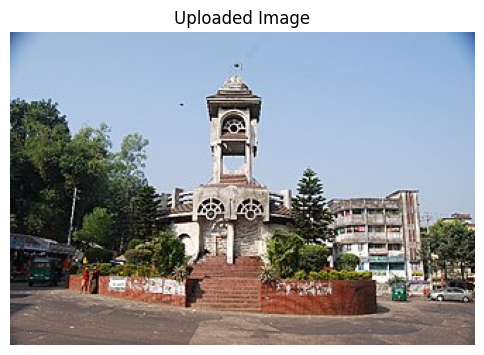


RESNET-50 PREDICTION
Predicted Landmark : Cheragi_Pahar
Confidence         : 43.76%
Class Index        : 20


In [ ]:
# CELL 40 — UPLOAD IMAGE AND TEST RESNET-50

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import os

# ------------------------------------------------------------
# 1. Upload image
# ------------------------------------------------------------

uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("No image was uploaded.")

image_path = list(uploaded.keys())[0]

print("Uploaded image:")
print(image_path)


# ------------------------------------------------------------
# 2. Load BEST ResNet-50 model
# ------------------------------------------------------------

checkpoint = torch.load(
    FINAL_MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

CLASS_NAMES = checkpoint["class_names"]
IMG_SIZE = checkpoint["image_size"]


# ------------------------------------------------------------
# 3. Preprocessing
#    Must match validation/test preprocessing
# ------------------------------------------------------------

inference_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


# ------------------------------------------------------------
# 4. Open image
# ------------------------------------------------------------

image = Image.open(
    image_path
).convert("RGB")


# ------------------------------------------------------------
# 5. Display image
# ------------------------------------------------------------

plt.figure(figsize=(6, 6))

plt.imshow(image)

plt.axis("off")

plt.title("Uploaded Image")

plt.show()


# ------------------------------------------------------------
# 6. Prepare image
# ------------------------------------------------------------

input_tensor = inference_transform(
    image
).unsqueeze(0)

input_tensor = input_tensor.to(device)


# ------------------------------------------------------------
# 7. Prediction
# ------------------------------------------------------------

with torch.no_grad():

    output = model(
        input_tensor
    )

    probabilities = F.softmax(
        output,
        dim=1
    )

    confidence, predicted_idx = torch.max(
        probabilities,
        dim=1
    )


predicted_idx = predicted_idx.item()

confidence = confidence.item()

predicted_class = CLASS_NAMES[
    predicted_idx
]


# ------------------------------------------------------------
# 8. Display result
# ------------------------------------------------------------

print("\n" + "=" * 60)

print("RESNET-50 PREDICTION")

print("=" * 60)

print(
    f"Predicted Landmark : {predicted_class}"
)

print(
    f"Confidence         : {confidence * 100:.2f}%"
)

print(
    f"Class Index        : {predicted_idx}"
)

print("=" * 60)

Saving Andarkilla_Mosque_from_south.jpg to Andarkilla_Mosque_from_south.jpg
Uploaded image:
Andarkilla_Mosque_from_south.jpg


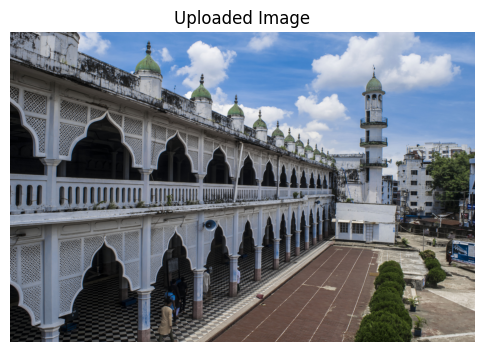


RESNET-50 PREDICTION
Predicted Landmark : Anderkilla_Shahi_Jame_Mosque
Confidence         : 34.89%
Class Index        : 2


In [ ]:
# ============================================================
# CELL 40 — UPLOAD IMAGE AND TEST RESNET-50
# ============================================================

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import os

# ------------------------------------------------------------
# 1. Upload image
# ------------------------------------------------------------

uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("No image was uploaded.")

image_path = list(uploaded.keys())[0]

print("Uploaded image:")
print(image_path)


# ------------------------------------------------------------
# 2. Load BEST ResNet-50 model
# ------------------------------------------------------------

checkpoint = torch.load(
    FINAL_MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

CLASS_NAMES = checkpoint["class_names"]
IMG_SIZE = checkpoint["image_size"]


# ------------------------------------------------------------
# 3. Preprocessing
#    Must match validation/test preprocessing
# ------------------------------------------------------------

inference_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


# ------------------------------------------------------------
# 4. Open image
# ------------------------------------------------------------

image = Image.open(
    image_path
).convert("RGB")


# ------------------------------------------------------------
# 5. Display image
# ------------------------------------------------------------

plt.figure(figsize=(6, 6))

plt.imshow(image)

plt.axis("off")

plt.title("Uploaded Image")

plt.show()


# ------------------------------------------------------------
# 6. Prepare image
# ------------------------------------------------------------

input_tensor = inference_transform(
    image
).unsqueeze(0)

input_tensor = input_tensor.to(device)


# ------------------------------------------------------------
# 7. Prediction
# ------------------------------------------------------------

with torch.no_grad():

    output = model(
        input_tensor
    )

    probabilities = F.softmax(
        output,
        dim=1
    )

    confidence, predicted_idx = torch.max(
        probabilities,
        dim=1
    )


predicted_idx = predicted_idx.item()

confidence = confidence.item()

predicted_class = CLASS_NAMES[
    predicted_idx
]


# ------------------------------------------------------------
# 8. Display result
# ------------------------------------------------------------

print("\n" + "=" * 60)

print("RESNET-50 PREDICTION")

print("=" * 60)

print(
    f"Predicted Landmark : {predicted_class}"
)

print(
    f"Confidence         : {confidence * 100:.2f}%"
)

print(
    f"Class Index        : {predicted_idx}"
)

print("=" * 60)

In [10]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/Chattogram_Landmark_Dataset"

print("Project folder exists:", os.path.exists(PROJECT_ROOT))

if os.path.exists(PROJECT_ROOT):
    print("Project contents:", os.listdir(PROJECT_ROOT))

Project folder exists: True
Project contents: ['01_inventory', '02_availability', '03_candidates', '04_review', '05_final_dataset', '06_train_val_test', '07_models', '08_results', '09_cache']


In [11]:
import os

drive_root = "/content/drive/MyDrive"
target_name = "ResNet50_App_Best.pth"
matches = []

for root, dirs, files in os.walk(drive_root):
    # Skip common folders that are unlikely to contain the model
    dirs[:] = [
        d for d in dirs
        if d not in {".ipynb_checkpoints", ".git"}
    ]

    if target_name in files:
        matches.append(os.path.join(root, target_name))

print("Checkpoint matches:")
for path in matches:
    print(path)

if not matches:
    print("Checkpoint not found in MyDrive.")

Checkpoint matches:
/content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/Model/Resnet50 App/ResNet50_App_Best.pth


In [12]:
FINAL_MODEL_PATH = matches[0]
print("Loading:", FINAL_MODEL_PATH)

Loading: /content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/Model/Resnet50 App/ResNet50_App_Best.pth


In [13]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    FINAL_MODEL_PATH,
    map_location=device,
    weights_only=False
)

CLASS_NAMES = checkpoint["class_names"]
NUM_CLASSES = checkpoint["num_classes"]

model = models.resnet50(weights=None)
in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.50),
    nn.Linear(in_features, NUM_CLASSES)
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("ResNet-50 checkpoint loaded successfully.")
print("Number of classes:", NUM_CLASSES)

ResNet-50 checkpoint loaded successfully.
Number of classes: 58


In [14]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    FINAL_MODEL_PATH,
    map_location=device,
    weights_only=False
)

CLASS_NAMES = checkpoint["class_names"]
NUM_CLASSES = checkpoint["num_classes"]

model = models.resnet50(weights=None)

in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.50),
    nn.Linear(in_features, NUM_CLASSES)
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Model loaded successfully!")
print("Number of classes:", NUM_CLASSES)

Model loaded successfully!
Number of classes: 58


In [15]:
print("Test loader exists:", "test_loader" in globals())

if "test_loader" in globals():
    print("Test images:", len(test_loader.dataset))

Test loader exists: False


In [16]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_ROOT = "/content/drive/MyDrive/Chattogram_Landmark_Dataset"
TEST_DIR = os.path.join(PROJECT_ROOT, "06_train_val_test", "test")

print("Project folder exists:", os.path.exists(PROJECT_ROOT))
print("Test folder exists:", os.path.exists(TEST_DIR))

if os.path.exists(TEST_DIR):
    print("Sample test folders:", os.listdir(TEST_DIR)[:10])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder exists: True
Test folder exists: True
Sample test folders: ['Bandarban', 'Brahmanbaria', 'Chandpur', 'Chattogram', 'Coxs_Bazar', 'Cumilla', 'Khagrachhari', 'Lakshmipur', 'Noakhali', 'Rangamati']


In [17]:
import os
import torch
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

PROJECT_ROOT = "/content/drive/MyDrive/Chattogram_Landmark_Dataset"
DATASET_ROOT = os.path.join(PROJECT_ROOT, "06_train_val_test")
TRAIN_DIR = os.path.join(DATASET_ROOT, "train")
TEST_DIR = os.path.join(DATASET_ROOT, "test")

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".webp")

def get_landmark_classes(split_dir):
    classes = set()

    for district in sorted(os.listdir(split_dir)):
        district_path = os.path.join(split_dir, district)

        if not os.path.isdir(district_path):
            continue

        for landmark in sorted(os.listdir(district_path)):
            landmark_path = os.path.join(district_path, landmark)

            if os.path.isdir(landmark_path):
                classes.add(landmark)

    return sorted(classes)

CLASS_NAMES = get_landmark_classes(TRAIN_DIR)
NUM_CLASSES = len(CLASS_NAMES)

print("Number of classes:", NUM_CLASSES)

Number of classes: 58


In [18]:
class LandmarkDataset(Dataset):
    def __init__(self, root_dir, class_names, transform=None):
        self.class_to_idx = {
            name: idx for idx, name in enumerate(class_names)
        }
        self.transform = transform
        self.samples = []

        for district in sorted(os.listdir(root_dir)):
            district_path = os.path.join(root_dir, district)

            if not os.path.isdir(district_path):
                continue

            for landmark in sorted(os.listdir(district_path)):
                landmark_path = os.path.join(district_path, landmark)

                if not os.path.isdir(landmark_path):
                    continue

                if landmark not in self.class_to_idx:
                    continue

                label = self.class_to_idx[landmark]

                for filename in sorted(os.listdir(landmark_path)):
                    if filename.lower().endswith(IMAGE_EXTENSIONS):
                        self.samples.append((
                            os.path.join(landmark_path, filename),
                            label
                        ))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


val_test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset = LandmarkDataset(
    TEST_DIR,
    CLASS_NAMES,
    transform=val_test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Test images:", len(test_dataset))
print("Test loader created successfully.")

Test images: 328
Test loader created successfully.


In [19]:
print("Test loader exists:", "test_loader" in globals())
print("Number of classes:", NUM_CLASSES)
print("Number of test batches:", len(test_loader))

Test loader exists: True
Number of classes: 58
Number of test batches: 11


In [20]:
import os

drive_root = "/content/drive/MyDrive"
checkpoint_name = "ResNet50_App_Best.pth"
matches = []

for root, dirs, files in os.walk(drive_root):
    dirs[:] = [
        d for d in dirs
        if d not in {".ipynb_checkpoints", ".git"}
    ]

    if checkpoint_name in files:
        matches.append(os.path.join(root, checkpoint_name))

print("Checkpoint files found:", len(matches))

for path in matches:
    print(path)

Checkpoint files found: 1
/content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/Model/Resnet50 App/ResNet50_App_Best.pth


In [21]:
import torch
import torch.nn as nn
from torchvision import models

if not matches:
    raise FileNotFoundError(
        "Checkpoint not found. We need to locate the saved .pth file first."
    )

FINAL_MODEL_PATH = matches[0]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    FINAL_MODEL_PATH,
    map_location=device,
    weights_only=False
)

CLASS_NAMES = checkpoint["class_names"]
NUM_CLASSES = checkpoint["num_classes"]

model = models.resnet50(weights=None)
in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.50),
    nn.Linear(in_features, NUM_CLASSES)
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Model loaded successfully!")
print("Checkpoint:", FINAL_MODEL_PATH)
print("Classes:", NUM_CLASSES)

Model loaded successfully!
Checkpoint: /content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/Model/Resnet50 App/ResNet50_App_Best.pth
Classes: 58


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np

all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)

print(f"Test images: {len(all_labels)}")
print(f"Accuracy: {accuracy_score(all_labels, all_predictions):.4f}")
print(f"Macro Precision: {precision_score(all_labels, all_predictions, average='macro', zero_division=0):.4f}")
print(f"Macro Recall: {recall_score(all_labels, all_predictions, average='macro', zero_division=0):.4f}")
print(f"Macro F1-score: {f1_score(all_labels, all_predictions, average='macro', zero_division=0):.4f}")
print(f"Weighted F1-score: {f1_score(all_labels, all_predictions, average='weighted', zero_division=0):.4f}")

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    zero_division=0
))

Test images: 328
Accuracy: 0.5549
Macro Precision: 0.5864
Macro Recall: 0.5549
Macro F1-score: 0.5447
Weighted F1-score: 0.5460

Classification report:
                                  precision    recall  f1-score   support

                  Adinath_Temple       0.75      0.50      0.60         6
                    Alutila_Cave       0.00      0.00      0.00         5
    Anderkilla_Shahi_Jame_Mosque       0.83      0.83      0.83         6
                  Anderson_Canal       0.40      0.40      0.40         5
                  Arifail_Mosque       1.00      0.75      0.86         4
              Bajra_Shahi_Mosque       1.00      0.40      0.57         5
                Banshbaria_Beach       0.60      0.50      0.55         6
                     Batali_Hill       0.29      0.33      0.31         6
          Bayazid_Bostami_Shrine       0.33      0.17      0.22         6
                       Boga_Lake       0.83      0.83      0.83         6
        Central_Railway_Building 

In [23]:
import pandas as pd

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(CLASS_NAMES)))
)

cm_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

cm_df.to_csv(
    "/content/drive/MyDrive/ResNet50_confusion_matrix.csv"
)

print("Confusion matrix saved to Google Drive.")

Confusion matrix saved to Google Drive.


In [24]:

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.metrics import confusion_matrix, accuracy_score

# Evaluate the trained ResNet-50 model
model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)

# Ensure all 58 classes are represented in the matrix
num_classes = len(CLASS_NAMES)
class_indices = list(range(num_classes))

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=class_indices
)

print("Confusion matrix shape:", cm.shape)
print("Test images evaluated:", len(all_labels))
print(f"Test accuracy: {accuracy_score(all_labels, all_predictions):.2%}")

assert cm.shape == (58, 58), f"Expected (58, 58), got {cm.shape}"


Confusion matrix shape: (58, 58)
Test images evaluated: 328
Test accuracy: 55.49%


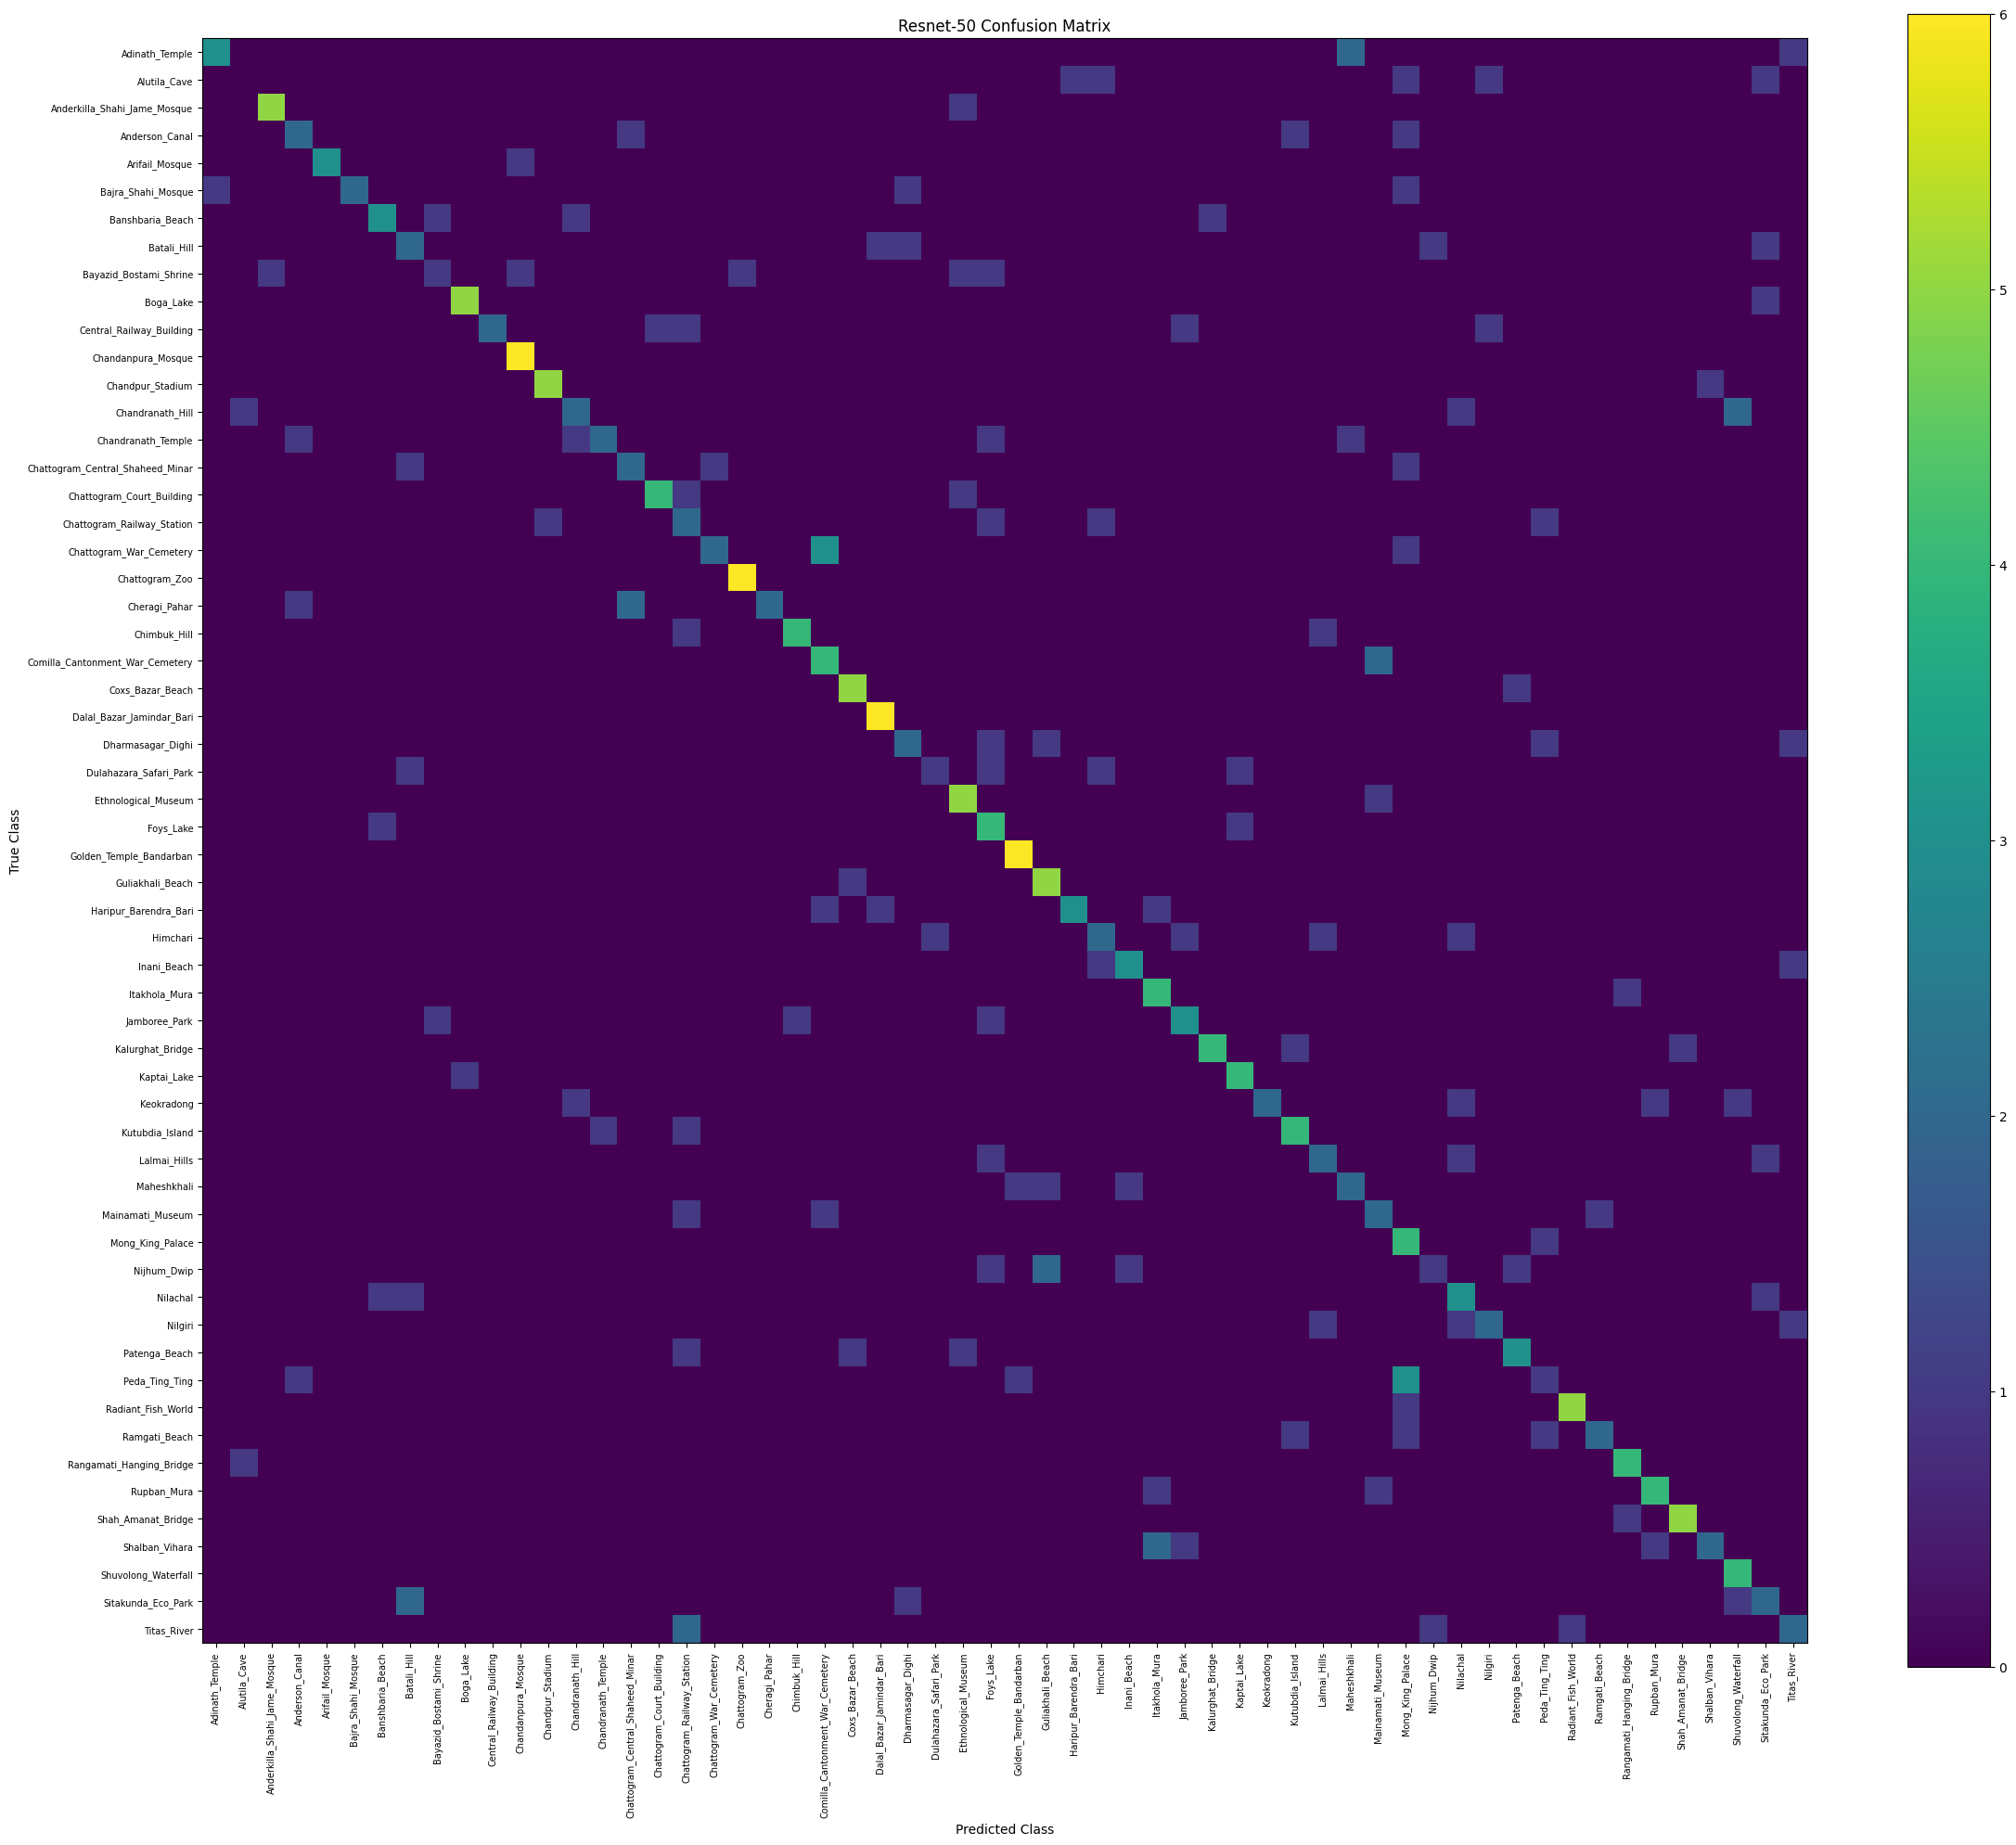

In [28]:
plt.figure(
    figsize=(24, 20)
)

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "Resnet-50 Confusion Matrix"
)

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    CLASS_NAMES,
    rotation=90,
    fontsize=7
)

plt.yticks(
    range(NUM_CLASSES),
    CLASS_NAMES,
    fontsize=7
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.tight_layout()

plt.show()

In [26]:

# Save numeric confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

cm_df.index.name = "Actual Class"
cm_df.columns.name = "Predicted Class"

csv_path = "/content/drive/MyDrive/ResNet50_Confusion_Matrix.csv"
cm_df.to_csv(csv_path)

# Save the image to Google Drive
image_drive_path = (
    "/content/drive/MyDrive/ResNet50_Confusion_Matrix.png"
)

plt.figure(figsize=(26, 22))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    square=True
)
plt.title("ResNet-50 Confusion Matrix — Test Dataset")
plt.xlabel("Predicted Landmark Class")
plt.ylabel("Actual Landmark Class")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.savefig(image_drive_path, dpi=300, bbox_inches="tight")
plt.close()

print("CSV saved:", csv_path)
print("Image saved:", image_drive_path)


CSV saved: /content/drive/MyDrive/ResNet50_Confusion_Matrix.csv
Image saved: /content/drive/MyDrive/ResNet50_Confusion_Matrix.png
